# Dynamic Minimum-VaR Portfolio

This notebook repeats the Stage 3 construction (`portoflio.ipynb`) but lets the portfolio **reallocate** as time passes. $10,000 is invested at the start of 2018 and the target expected year-on-year return is the same. At every rebalance date, **the whole accumulated value** is re-split across the NIFTY 50, S&P 500 and Euro Stoxx 50 so that the forecast VaR over the coming period is as low as possible while still meeting the target.

**What changes at each rebalance date $d$.** Only data up to and including the close on day $d$ is used:

| Input | Static portfolio (Stage 3) | Dynamic portfolio (this notebook) |
|:--|:--|:--|
| GARCH parameters | fitted once on data to 2017 | **re-estimated** on all data up to $d$ (expanding window) |
| Volatility forecast | average over all of 2018–2025, made in Dec 2017 | average over the **next holding period only**, made at $d$ |
| Correlations | training-period residuals | **DCC-GARCH** conditional correlations, re-estimated and forecast over the holding period (`CORR_MODEL = "dcc"`), or a rolling window (`"rolling"`) |
| Expected returns | training-period mean | mean of all returns up to $d$ (expanding) |
| Weights | set once, then drift | **reset** to the new optimum, using the accumulated value |

**"Minimise risk when possible."** At each date the optimiser finds the lowest-VaR mix whose expected return meets the target. If no long-only mix can reach the target (the target is above every index's expected return at that time), it falls back to the rule set by `IF_INFEASIBLE` and records the date.

The dynamic portfolio is compared with the same strategy using rolling-window correlations, with the static Stage 3 portfolio and with holding each index alone.

**Assumptions.** These are the same as in Stage 3: local-currency (hedged) price returns, no dividends, and fractional holdings. Transaction costs are a parameter, set to zero by default.

In [1]:
# ===================== USER PARAMETERS =====================
INITIAL_INVESTMENT   = 10_000     # dollars
TARGET_RETURN        = 0.08       # target expected year-on-year return (same as Stage 3)
VAR_LEVEL            = 0.99       # VaR confidence level used in the optimisation
ALLOW_SHORT          = False      # False: weights between 0 and 1

REBALANCE_FREQ       = "M"        # "W" weekly, "M" monthly, "Q" quarterly
REFIT_GARCH          = True       # re-estimate GARCH parameters at every rebalance
CORR_MODEL           = "dcc"      # "dcc" (DCC-GARCH conditional correlations) or "rolling"
CORR_WINDOW          = 500        # trading days of residuals for the rolling correlation matrix (None = expanding)
RETURN_WINDOW        = None       # trading days for expected returns (None = expanding since 2007)
IF_INFEASIBLE        = "max_return"   # target unreachable: "max_return" (closest to target) or "min_var"
TRANSACTION_COST_BPS = 0.0        # cost per unit of turnover, in basis points (10 = 0.10%)
# ===========================================================

In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from arch import arch_model
from scipy import stats
from scipy.optimize import minimize

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.4f}".format)

SPLIT = "2018-01-01"
DATA = Path("data")
INDICES = {"NIFTY 50": "nifty50", "S&P 500": "sp500", "Euro Stoxx 50": "eurostoxx50"}
NAMES = list(INDICES)
COLORS = {"Dynamic portfolio": "crimson", "Dynamic (rolling corr)": "mediumpurple", "Static portfolio": "k",
          "NIFTY 50": "C1", "S&P 500": "C0", "Euro Stoxx 50": "C2"}

## 1. Data

The data and calendar are the same as in Stage 3. Prices are aligned on the union of the three markets' trading days, and a closed market's price is carried forward, so its return is zero that day. GARCH models are fitted on each index's own trading days.

In [3]:
def load_prices(slug):
    p = pd.read_csv(DATA / f"{slug}_daily.csv", index_col="Date", parse_dates=True)["Close"]
    return p.dropna()[lambda s: ~s.index.duplicated()]

own_prices = {n: load_prices(s) for n, s in INDICES.items()}
own_ret = {n: (100 * np.log(p).diff()).dropna() for n, p in own_prices.items()}
P = pd.DataFrame(own_prices).ffill().dropna()[NAMES]
simple_ret = P.pct_change().dropna()

last_train = P.index[P.index < SPLIT][-1]
test_idx = P.index[P.index >= SPLIT]
full_models = {n: arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t")
               for n, r in own_ret.items()}
print(f"Common calendar {P.index[0].date()} -> {P.index[-1].date()};  "
      f"test {test_idx[0].date()} -> {test_idx[-1].date()} ({len(test_idx)} days)")

Common calendar 2007-09-17 -> 2025-12-31;  test 2018-01-02 -> 2025-12-31 (2073 days)


## 2. Building blocks

### 2a. Model at a rebalance date

`fit_at(name, d)` estimates GJR-GARCH(1,1,1)-t on the index's returns **up to and including day $d$**. Its parameters are then *fixed* on the full return series, which gives:

* in-sample standardised residuals up to $d$, used for correlations,
* a multi-step variance forecast from $d$, used for planning, and
* one-step-ahead variance forecasts for each day of the holding period, using the actual returns as they arrive but no re-estimation, used for daily VaR monitoring.

Results are cached so that each (index, date) pair is fitted only once.

In [4]:
_cache = {}

def fit_at(name, d):
    key = (name, d)
    if key not in _cache:
        r = own_ret[name][own_ret[name].index <= d]
        res = arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")
        fixed = full_models[name].fix(res.params.values)
        z_all = fixed.resid / fixed.conditional_volatility
        _cache[key] = {"params": res.params, "fixed": fixed, "z_all": z_all,
                       "z": z_all[z_all.index <= d]}
    return _cache[key]

def own_last(name, d):
    idx = own_ret[name].index
    return idx[idx <= d][-1]

### 2a-bis. DCC-GARCH correlations

The univariate GJR-GARCH models give each index's volatility. **DCC** (Dynamic Conditional Correlation; Engle, 2002) adds correlations that change over time. These are built from the standardised residuals $z_t$ on days when all three markets traded:

$$Q_t = (1 - a - b)\,\bar Q + a\, z_{t-1} z_{t-1}^\top + b\, Q_{t-1}, \qquad R_t = \text{diag}(Q_t)^{-1/2}\, Q_t\, \text{diag}(Q_t)^{-1/2}$$

* $\bar Q$ is the long-run average of $z_t z_t^\top$.
* $a$ is the **reaction** of correlations to yesterday's joint shock.
* $b$ is their **persistence**.
* When $a = b = 0$, correlations are constant.

**Estimation.** $a$ and $b$ are estimated by maximising the correlation part of the Gaussian likelihood, $-\tfrac12 \sum_t\left(\ln|R_t| + z_t^\top R_t^{-1} z_t - z_t^\top z_t\right)$. This is the standard two-step DCC estimator, run on all residuals up to each rebalance date.

**Forecast.** Over a holding period of $H$ days, $Q_{d+h} \approx \bar Q + (a + b)^{h-1}(Q_{d+1} - \bar Q)$. The planning correlation is the average of the implied $R_{d+h}$ over the period (Engle & Sheppard, 2001). After a crisis, when correlations are high, the forecast starts high and reverts towards normal.

**Daily monitoring.** Within the holding period, $Q_t$ is updated every day with the realised residuals, keeping $a$ and $b$ fixed. So the portfolio VaR reflects correlation spikes as they happen.

In [5]:
from scipy.signal import lfilter

def dcc_filter(Z, a, b, Qbar, Q0=None):
    # returns (T+1, k, k): element t is the Q used on day t; the last element is the next-day forecast
    T, k = Z.shape
    Q0 = Qbar if Q0 is None else Q0
    out = np.empty((T + 1, k * k)); out[0] = Q0.reshape(-1)
    if T == 0:
        return out.reshape(1, k, k)
    zz = np.einsum("ti,tj->tij", Z, Z).reshape(T, -1)
    x = (1 - a - b) * Qbar.reshape(1, -1) + a * zz
    for j in range(k * k):                       # Q is linear in its own past -> one IIR filter per element
        out[1:, j], _ = lfilter([1.0], [1.0, -b], x[:, j], zi=[b * Q0.reshape(-1)[j]])
    return out.reshape(T + 1, k, k)

def q_to_r(Q):
    dg = np.sqrt(np.einsum("...ii->...i", Q))
    return Q / (dg[..., :, None] * dg[..., None, :])

def dcc_nll(p, Z, Qbar):
    a, b = p
    if a < 0 or b < 0 or a + b >= 0.999:
        return 1e10
    R = q_to_r(dcc_filter(Z, a, b, Qbar)[:-1])
    _, logdet = np.linalg.slogdet(R)
    quad = np.einsum("ti,tij,tj->t", Z, np.linalg.inv(R), Z)
    return 0.5 * np.sum(logdet + quad - (Z ** 2).sum(1))

_dcc_cache = {}

def dcc_at(d, param_date):
    # DCC(1,1) estimated on joint standardised residuals up to d -> (a, b, Qbar, Q_next)
    key = (d, param_date)
    if key not in _dcc_cache:
        z = pd.DataFrame({n: fit_at(n, param_date)["z_all"] for n in NAMES}).dropna()
        Z = z[(z.index >= P.index[0]) & (z.index <= d)].values
        Qbar = Z.T @ Z / len(Z)
        res = minimize(dcc_nll, (0.02, 0.95), args=(Z, Qbar), method="L-BFGS-B",
                       bounds=[(1e-6, 0.5), (1e-6, 0.998)])
        a, b = res.x
        _dcc_cache[key] = (a, min(b, 0.998 - a), Qbar, dcc_filter(Z, a, min(b, 0.998 - a), Qbar)[-1])
    return _dcc_cache[key]

def dcc_planning_R(dcc, H):
    a, b, Qbar, Qn = dcc
    decay = (a + b) ** np.arange(H)
    return q_to_r(Qbar[None] + decay[:, None, None] * (Qn - Qbar)[None]).mean(axis=0)

# DCC on the training period, as an illustration
_a, _b, _Qbar, _ = dcc_at(P.index[P.index < SPLIT][-1], P.index[P.index < SPLIT][-1])
print(f"DCC(1,1) on data to 2017: a = {_a:.4f}, b = {_b:.4f}, a + b = {_a + _b:.4f}")
print("Long-run correlation (Q-bar, normalised):")
pd.DataFrame(q_to_r(_Qbar), index=NAMES, columns=NAMES).round(3)

DCC(1,1) on data to 2017: a = 0.0223, b = 0.9257, a + b = 0.9480
Long-run correlation (Q-bar, normalised):


,NIFTY 50,S&P 500,Euro Stoxx 50
NIFTY 50,1.0000,0.2640,0.3900
S&P 500,0.2640,1.0000,0.6300
Euro Stoxx 50,0.3900,0.6300,1.0000


### 2b. Planning inputs at a rebalance date

For a holding period from $d$ to the next rebalance date:

* **Planning volatility** $\sigma_i^{plan} = \sqrt{\tfrac1H\sum_{h=1}^{H}\hat\sigma^2_{i,d+h|d}}$, the average forecast variance over the $H$ trading days of that index in the period.
* **Correlation** $R$: the DCC forecast averaged over the holding period or, with `CORR_MODEL = "rolling"`, the sample correlation of standardised residuals over the last `CORR_WINDOW` common trading days up to $d$.
* **Expected return** $\mu_i$: the mean daily simple return up to $d$, × 252 for the annual figure used in the constraint.
* **Tail parameter** $\nu_i$ from the current fit.

In [6]:
def planning_inputs(d, horizon_days, param_date, corr_window, return_window, corr_model=CORR_MODEL):
    fits = {n: fit_at(n, param_date) for n in NAMES}
    sig = []
    for n in NAMES:
        H = max(1, int(((own_ret[n].index > d) & (own_ret[n].index <= horizon_days[-1])).sum()))
        fc = fits[n]["fixed"].forecast(horizon=H, start=own_last(n, d), reindex=False)
        sig.append(np.sqrt(fc.variance.iloc[0].values.mean()))
    z = pd.DataFrame({n: fits[n]["z"] for n in NAMES}).dropna()
    z = z[(z.index >= P.index[0]) & (z.index <= d)]
    if corr_window:
        z = z.iloc[-corr_window:]
    sr = simple_ret[simple_ret.index <= d]
    if return_window:
        sr = sr.iloc[-return_window:]
    dcc = dcc_at(d, param_date) if corr_model == "dcc" else None
    R = dcc_planning_R(dcc, len(horizon_days)) if dcc is not None else z.corr().loc[NAMES, NAMES].values
    return {
        "mu_d": 100 * sr.mean()[NAMES].values,          # % daily
        "mu_a": 252 * sr.mean()[NAMES].values,          # fraction, annual
        "sig": np.array(sig),                           # % daily
        "R": R,
        "dcc": dcc,
        "NU": np.array([fits[n]["params"]["nu"] for n in NAMES]),
        "fits": fits,
    }

### 2c. Optimiser

This is the same objective as Stage 3:

$$\min_w\; -\left(w^\top\mu - q_{\nu(w)}\sqrt{w^\top D R D\,w}\right)\quad\text{s.t.}\quad w^\top\mu^{annual}\ge\text{target},\;\; \textstyle\sum w_i=1,\;\; 0\le w_i\le1$$

In [7]:
def t_quantile(c, nu):
    return stats.t.ppf(c, nu) * np.sqrt((nu - 2) / nu)        # unit-variance Student-t

def port_var(w, inp, c=VAR_LEVEL):
    cov = np.outer(inp["sig"], inp["sig"]) * inp["R"]
    return -(w @ inp["mu_d"] - t_quantile(c, float(w @ inp["NU"])) * np.sqrt(max(w @ cov @ w, 0)))

def optimise(inp, target, c=VAR_LEVEL):
    # returns (weights, feasible flag)
    n = len(NAMES)
    if not ALLOW_SHORT and target > inp["mu_a"].max() + 1e-9:
        if IF_INFEASIBLE == "max_return":
            return np.eye(n)[np.argmax(inp["mu_a"])], False
        target = -np.inf
        feasible = False
    else:
        feasible = True
    bounds = None if ALLOW_SHORT else [(0, 1)] * n
    cons = [{"type": "eq", "fun": lambda w: w.sum() - 1}]
    if np.isfinite(target):
        cons.append({"type": "ineq", "fun": lambda w: w @ inp["mu_a"] - target})
    best = None
    for w0 in [np.full(n, 1 / n), np.eye(n)[np.argmax(inp["mu_a"])], *np.eye(n)]:
        res = minimize(port_var, w0, args=(inp, c), bounds=bounds, constraints=cons,
                       method="SLSQP", options={"ftol": 1e-12, "maxiter": 500})
        if res.success and (best is None or res.fun < best.fun):
            best = res
    w = best.x if best is not None else np.eye(n)[np.argmax(inp["mu_a"])]
    if not ALLOW_SHORT:
        w = np.clip(w, 0, None)
    return w / w.sum(), feasible

### 2d. Strategy simulator

A single engine runs every strategy:

1. **On each rebalance date $d$** (the last trading day of each week, month or quarter):
   * compute the current value $V_d$ of the holdings,
   * re-fit the models (if `REFIT_GARCH`), build the planning inputs and solve for new weights $w_d$,
   * pay transaction costs of $\text{bps} \times \sum_i |w_{d,i} - w^{drift}_{d,i}| \times V_d$, and
   * buy units $V_d\,w_{d,i} / P_{i,d}$ of each index.
2. **On every day in between**, hold the units (the weights drift) and compute the one-day VaR from the one-step GARCH volatility forecasts, the current drifted weights and that day's correlation matrix. With DCC, the matrix is updated daily from the realised residuals. With rolling correlations, it is the matrix from the last rebalance.

With `freq=None` and fixed weights, the same engine reproduces the static Stage 3 portfolio and the single-index portfolios.

In [8]:
def rebalance_dates(freq):
    if freq is None:
        return [last_train]
    idx = P.index[P.index >= last_train]
    ends = idx.to_series().groupby(idx.to_period(freq)).last()
    ends = [d for d in ends if last_train < d < test_idx[-1]]
    return [last_train] + ends

def run_strategy(freq=REBALANCE_FREQ, refit=REFIT_GARCH, target=TARGET_RETURN,
                 corr_window=CORR_WINDOW, return_window=RETURN_WINDOW,
                 tc_bps=TRANSACTION_COST_BPS, fixed_weights=None, corr_model=CORR_MODEL):
    dates = rebalance_dates(freq)
    units, rows, log = None, [], []
    for k, d in enumerate(dates):
        end = dates[k + 1] if k + 1 < len(dates) else test_idx[-1]
        days = P.index[(P.index > d) & (P.index <= end)]
        if len(days) == 0:
            continue
        inp = planning_inputs(d, days, d if refit else last_train, corr_window, return_window, corr_model)

        if fixed_weights is not None:
            w, feasible = np.asarray(fixed_weights, float), True
        else:
            w, feasible = optimise(inp, target)

        px = P.loc[d].values
        if units is None:
            V, w_drift, cost = INITIAL_INVESTMENT, None, 0.0
        else:
            V = float(units @ px)
            w_drift = units * px / V
            cost = tc_bps / 1e4 * np.abs(w - w_drift).sum() * V
            V -= cost
        turnover = 0.0 if w_drift is None else 0.5 * np.abs(w - w_drift).sum()
        units = V * w / px
        log.append({"date": d, **dict(zip(NAMES, w)), "feasible": feasible, "turnover": turnover,
                    "cost": cost, "value": V, "exp_return": w @ inp["mu_a"],
                    "planned_VaR": port_var(w, inp), **{f"mu {n}": m for n, m in zip(NAMES, inp["mu_a"])},
                    "dcc_a": inp["dcc"][0] if inp["dcc"] is not None else np.nan,
                    "dcc_b": inp["dcc"][1] if inp["dcc"] is not None else np.nan})

        # one-step-ahead sigma / mu on each index's own days, mapped to the common calendar
        sig_t, mu_t = {}, {}
        for n in NAMES:
            fc = inp["fits"][n]["fixed"].forecast(horizon=1, start=own_last(n, d), reindex=False)
            s = np.sqrt(fc.variance["h.1"]).shift(1)
            m = fc.mean["h.1"].shift(1)
            is_open = days.isin(own_ret[n].index)
            sig_t[n] = np.where(is_open, s.reindex(days).ffill().values, 0.0)
            mu_t[n] = np.where(is_open, m.reindex(days).ffill().values, 0.0)
        sig_t, mu_t = pd.DataFrame(sig_t, index=days), pd.DataFrame(mu_t, index=days)

        # correlation matrix for each day of the period
        if inp["dcc"] is not None:
            a_, b_, Qbar_, Qn_ = inp["dcc"]
            zall = pd.DataFrame({n: inp["fits"][n]["z_all"] for n in NAMES}).dropna()
            zf = zall[(zall.index > d) & (zall.index <= end)]
            Qseq = dcc_filter(zf.values, a_, b_, Qbar_, Q0=Qn_)
            R_path = q_to_r(Qseq[np.searchsorted(zf.index.values, days.values, side="left")])
        else:
            R_path = np.broadcast_to(inp["R"], (len(days), 3, 3))

        hold = P.loc[days].values * units
        prev_hold = np.vstack([units * px, hold[:-1]])
        prev_val = prev_hold.sum(axis=1)
        w_t = prev_hold / prev_val[:, None]
        X = w_t * sig_t.values
        pvar = np.einsum("ni,nij,nj->n", X, R_path, X)
        nu_t = w_t @ inp["NU"]
        var_pct = -((w_t * mu_t.values).sum(axis=1) - t_quantile(VAR_LEVEL, nu_t) * np.sqrt(pvar))
        val = hold.sum(axis=1)
        rows.append(pd.DataFrame({
            "value": val, "prev_value": prev_val,
            "ret_pct": 100 * (val / prev_val - 1), "log_ret_pct": 100 * np.log(val / prev_val),
            "VaR_pct": var_pct, "port_sigma": np.sqrt(pvar),
            **{f"w {n}": w_t[:, i] for i, n in enumerate(NAMES)},
            "rho NIFTY-S&P": R_path[:, 0, 1], "rho NIFTY-Euro": R_path[:, 0, 2], "rho S&P-Euro": R_path[:, 1, 2],
        }, index=days))
        # costs reduce value at the rebalance itself; record against the first day of the period
        rows[-1].iloc[0, rows[-1].columns.get_loc("prev_value")] += cost
        rows[-1].iloc[0, rows[-1].columns.get_loc("ret_pct")] = 100 * (val[0] / (prev_val[0] + cost) - 1)
        rows[-1].iloc[0, rows[-1].columns.get_loc("log_ret_pct")] = 100 * np.log(val[0] / (prev_val[0] + cost))

    out = pd.concat(rows)
    out["VaR_usd"] = out["VaR_pct"] / 100 * out["prev_value"]
    out["loss_usd"] = out["prev_value"] - out["value"]
    return out, pd.DataFrame(log).set_index("date")

## 3. Run the strategies

* **Dynamic portfolio:** rebalanced every `REBALANCE_FREQ` with the settings above (DCC correlations by default).
* **Dynamic (rolling corr):** identical, except that correlations come from a rolling `CORR_WINDOW`-day window. This was the Stage 5 version before DCC was added. The difference between the two isolates what DCC contributes.
* **Static portfolio:** the Stage 3 construction, using training-period inputs, one allocation and then buy and hold. It is re-run here with the same engine as a check.
* **Single indices:** 100% in each index, buy and hold.

In [9]:
dyn, dyn_log = run_strategy()
alt_model = "rolling" if CORR_MODEL == "dcc" else "dcc"
dyn_roll, dyn_roll_log = run_strategy(corr_model=alt_model)

_static_inp = planning_inputs(last_train, test_idx, last_train, None, None, "rolling")
static_w, _ = optimise(_static_inp, TARGET_RETURN)
static, static_log = run_strategy(freq=None, refit=False, corr_window=None, fixed_weights=static_w,
                                  corr_model="rolling")

ALT_LABEL = "Dynamic (rolling corr)" if CORR_MODEL == "dcc" else "Dynamic (DCC corr)"
COLORS.setdefault(ALT_LABEL, "mediumpurple")
results = {"Dynamic portfolio": dyn, ALT_LABEL: dyn_roll, "Static portfolio": static}
LOGS = {"Dynamic portfolio": dyn_log, ALT_LABEL: dyn_roll_log}
for i, n in enumerate(NAMES):
    results[n], _ = run_strategy(freq=None, refit=False, corr_window=None, fixed_weights=np.eye(3)[i],
                                 corr_model="rolling")

print(f"Rebalances: {len(dyn_log)}   "
      f"target infeasible on {(~dyn_log['feasible']).sum()} of them")
print("Static weights (check against Stage 3): "
      + ", ".join(f"{n} {w:.1%}" for n, w in zip(NAMES, static_w))
      + f"  -> final value ${static['value'].iloc[-1]:,.0f}")

Rebalances: 96   target infeasible on 1 of them
Static weights (check against Stage 3): NIFTY 50 33.5%, S&P 500 66.5%, Euro Stoxx 50 0.0%  -> final value $25,339


## 4. How the allocation moved

Top: the dynamic weights chosen at each rebalance date. Middle: the expected annual return of each index as estimated at each date, against the target. Bottom: the forecast VaR at each rebalance, planned for the coming period, for the dynamic portfolio and for each index alone.

,NIFTY 50,S&P 500,Euro Stoxx 50
mean,48.7%,43.5%,7.8%
min,11.1%,0.0%,0.0%
max,100.0%,85.3%,38.6%
share of rebalances held (>1%),100.0%,99.0%,58.3%


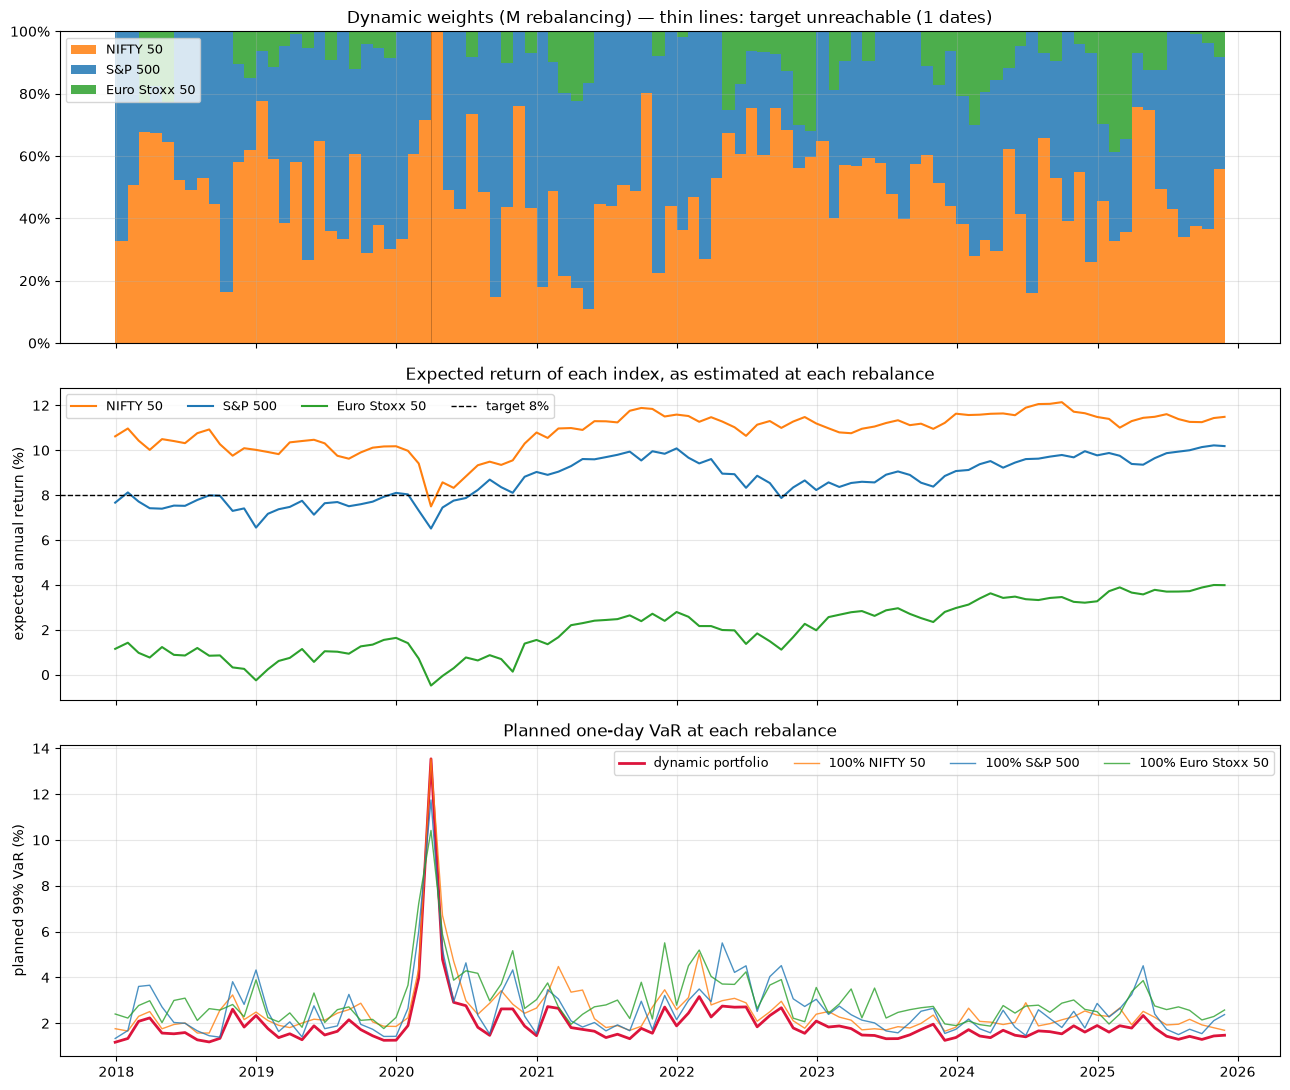

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(13, 11), sharex=True)
ax[0].stackplot(dyn_log.index, *[dyn_log[n] for n in NAMES], labels=NAMES,
                colors=[COLORS[n] for n in NAMES], alpha=0.85, step="post")
infeas = dyn_log.index[~dyn_log["feasible"]]
for d in infeas:
    ax[0].axvline(d, color="k", lw=0.4, alpha=0.4)
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax[0].set_ylim(0, 1)
ax[0].set_title(f"Dynamic weights ({REBALANCE_FREQ} rebalancing)"
                + (f" — thin lines: target unreachable ({len(infeas)} dates)" if len(infeas) else ""))
ax[0].legend(loc="upper left", fontsize=9)

for n in NAMES:
    ax[1].plot(dyn_log.index, 100 * dyn_log[f"mu {n}"], color=COLORS[n], label=n)
ax[1].axhline(100 * TARGET_RETURN, color="k", ls="--", lw=1, label=f"target {TARGET_RETURN:.0%}")
ax[1].set_ylabel("expected annual return (%)"); ax[1].legend(fontsize=9, ncol=4)
ax[1].set_title("Expected return of each index, as estimated at each rebalance")

ax[2].plot(dyn_log.index, dyn_log["planned_VaR"], color=COLORS["Dynamic portfolio"], lw=2, label="dynamic portfolio")
single_var = {}
for i, n in enumerate(NAMES):
    single_var[n] = [port_var(np.eye(3)[i], planning_inputs(d, P.index[(P.index > d)][:21], d, CORR_WINDOW, RETURN_WINDOW))
                     for d in dyn_log.index]
    ax[2].plot(dyn_log.index, single_var[n], color=COLORS[n], lw=1, alpha=0.8, label=f"100% {n}")
ax[2].set_ylabel(f"planned {VAR_LEVEL:.0%} VaR (%)"); ax[2].legend(fontsize=9, ncol=4)
ax[2].set_title("Planned one-day VaR at each rebalance")
plt.tight_layout()

summary_w = dyn_log[NAMES].describe().loc[["mean", "min", "max"]]
summary_w.loc["share of rebalances held (>1%)"] = (dyn_log[NAMES] > 0.01).mean()
summary_w.style.format("{:.1%}")

### Correlations: DCC vs rolling window

Daily correlations used for VaR monitoring by the two dynamic strategies, together with the DCC parameters re-estimated at each rebalance.

DCC a: 0.0136–0.0226,  a + b: 0.9447–0.9824


,DCC mean,DCC min,DCC max,rolling mean
rho NIFTY-S&P,0.2420,0.0670,0.4880,0.2260
rho NIFTY-Euro,0.3750,0.2220,0.6010,0.3690
rho S&P-Euro,0.5750,0.3490,0.7260,0.5400


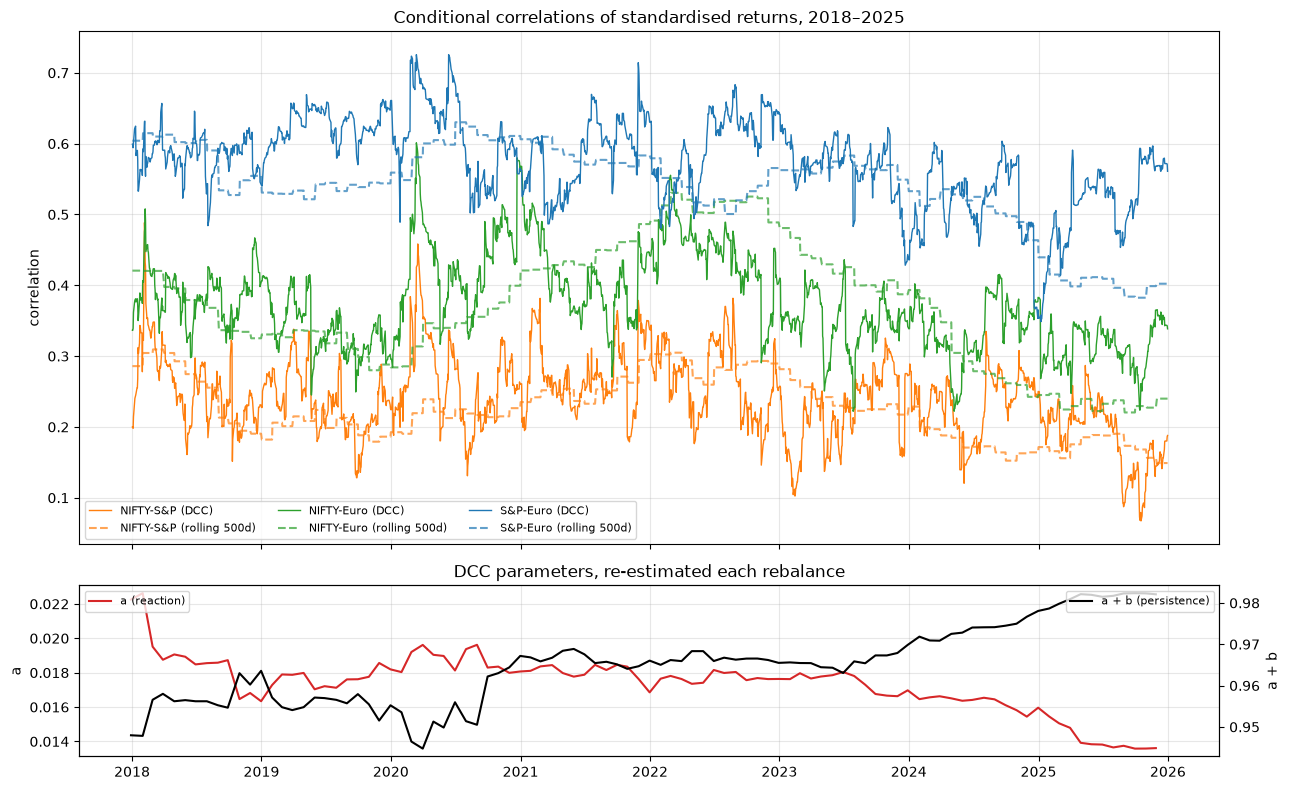

In [11]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
dcc_df = dyn if CORR_MODEL == "dcc" else dyn_roll
roll_df = dyn_roll if CORR_MODEL == "dcc" else dyn
for col, c in zip(["rho NIFTY-S&P", "rho NIFTY-Euro", "rho S&P-Euro"], ["C1", "C2", "C0"]):
    ax[0].plot(dcc_df.index, dcc_df[col], color=c, lw=1, label=f"{col[4:]} (DCC)")
    ax[0].plot(roll_df.index, roll_df[col], color=c, lw=1.5, ls="--", alpha=0.7, label=f"{col[4:]} (rolling 500d)")
ax[0].set_ylabel("correlation"); ax[0].legend(ncol=3, fontsize=8, loc="lower left")
ax[0].set_title("Conditional correlations of standardised returns, 2018–2025")
dlog = dyn_log if CORR_MODEL == "dcc" else dyn_roll_log
ax[1].plot(dlog.index, dlog["dcc_a"], label="a (reaction)", color="C3")
ax1b = ax[1].twinx(); ax1b.plot(dlog.index, dlog["dcc_a"] + dlog["dcc_b"], color="k", label="a + b (persistence)")
ax1b.grid(False); ax[1].set_ylabel("a"); ax1b.set_ylabel("a + b")
ax[1].set_title("DCC parameters, re-estimated each rebalance"); ax[1].legend(loc="upper left", fontsize=8)
ax1b.legend(loc="upper right", fontsize=8)
plt.tight_layout()

corr_summary = pd.DataFrame({
    "DCC mean": dcc_df[["rho NIFTY-S&P", "rho NIFTY-Euro", "rho S&P-Euro"]].mean(),
    "DCC min": dcc_df[["rho NIFTY-S&P", "rho NIFTY-Euro", "rho S&P-Euro"]].min(),
    "DCC max": dcc_df[["rho NIFTY-S&P", "rho NIFTY-Euro", "rho S&P-Euro"]].max(),
    "rolling mean": roll_df[["rho NIFTY-S&P", "rho NIFTY-Euro", "rho S&P-Euro"]].mean(),
})
print(f"DCC a: {dlog['dcc_a'].min():.4f}–{dlog['dcc_a'].max():.4f},  a + b: "
      f"{(dlog['dcc_a'] + dlog['dcc_b']).min():.4f}–{(dlog['dcc_a'] + dlog['dcc_b']).max():.4f}")
corr_summary.round(3)

## 5. Growth of $10,000 and daily VaR

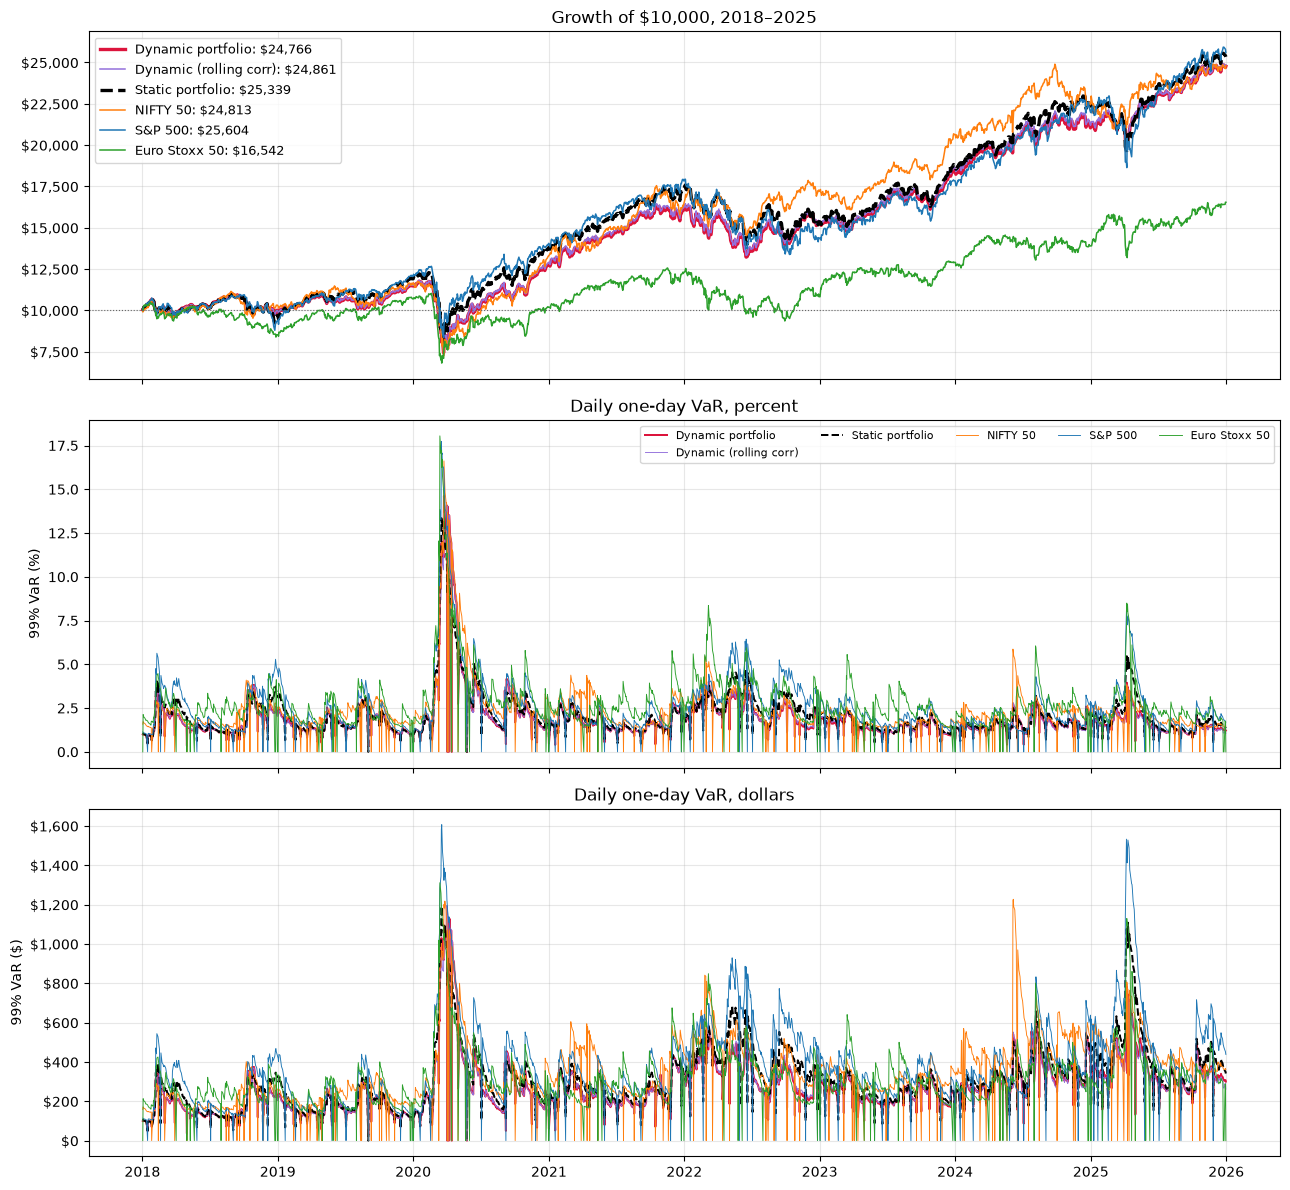

In [12]:
fig, ax = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for label, df in results.items():
    lw = 2.4 if "portfolio" in label else 1.1
    ls = "-" if label != "Static portfolio" else "--"
    ax[0].plot(df.index, df["value"], color=COLORS[label], lw=lw, ls=ls,
               label=f"{label}: ${df['value'].iloc[-1]:,.0f}")
    ax[1].plot(df.index, df["VaR_pct"], color=COLORS[label], lw=lw * 0.6, ls=ls, label=label)
    ax[2].plot(df.index, df["VaR_usd"], color=COLORS[label], lw=lw * 0.6, ls=ls, label=label)
ax[0].axhline(INITIAL_INVESTMENT, color="0.4", lw=0.8, ls=":")
ax[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[0].set_title(f"Growth of ${INITIAL_INVESTMENT:,}, 2018–2025"); ax[0].legend(loc="upper left", fontsize=9)
ax[1].set_ylabel(f"{VAR_LEVEL:.0%} VaR (%)"); ax[1].set_title("Daily one-day VaR, percent")
ax[2].set_ylabel(f"{VAR_LEVEL:.0%} VaR ($)"); ax[2].set_title("Daily one-day VaR, dollars")
ax[2].yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax[1].legend(fontsize=8, ncol=5)
plt.tight_layout()

## 6. Risk and return comparison

The metrics are the same as in Stage 3, plus three rows for the dynamic strategy: the number of rebalances, the average one-way turnover per rebalance and the total transaction costs. Green marks the best strategy on each row and red the worst.

In [13]:
def kupiec_p(hits, p):
    n, x = len(hits), int(hits.sum())
    if x == 0:
        lr = -2 * n * np.log(1 - p)
    else:
        pi = x / n
        lr = -2 * ((n - x) * np.log(1 - p) + x * np.log(p) - (n - x) * np.log(1 - pi) - x * np.log(pi))
    return 1 - stats.chi2.cdf(lr, 1)

def christoffersen_p(hits):
    h = hits.astype(int).values
    a, b = h[:-1], h[1:]
    n00, n01 = ((a == 0) & (b == 0)).sum(), ((a == 0) & (b == 1)).sum()
    n10, n11 = ((a == 1) & (b == 0)).sum(), ((a == 1) & (b == 1)).sum()
    ll = lambda k, q: k * np.log(q) if k else 0.0
    pi0 = n01 / max(n00 + n01, 1); pi1 = n11 / max(n10 + n11, 1); pi = (n01 + n11) / max(len(a), 1)
    lr = -2 * ((ll(n00 + n10, 1 - pi) + ll(n01 + n11, pi)) -
               (ll(n00, 1 - pi0) + ll(n01, pi0) + ll(n10, 1 - pi1) + ll(n11, pi1)))
    return 1 - stats.chi2.cdf(lr, 1)

def metrics(df, log=None):
    v = df["value"]
    years = len(df) / 252
    cagr = (v.iloc[-1] / INITIAL_INVESTMENT) ** (1 / years) - 1
    r = df["ret_pct"] / 100
    ye = v.groupby(v.index.year).last()
    yearly = ye / np.r_[INITIAL_INVESTMENT, ye.values[:-1]] - 1
    hits = df["log_ret_pct"] < -df["VaR_pct"]
    m = {
        "Final value ($)": v.iloc[-1],
        "Total return": v.iloc[-1] / INITIAL_INVESTMENT - 1,
        "Annualised return (CAGR)": cagr,
        "Best year": yearly.max(),
        "Worst year": yearly.min(),
        "Avg forecast 99% VaR (%)": df["VaR_pct"].mean(),
        "Avg forecast 99% VaR ($)": df["VaR_usd"].mean(),
        "Peak forecast 99% VaR ($)": df["VaR_usd"].max(),
        "Realised 1% daily return (%)": -np.percentile(df["ret_pct"], 1),
        "VaR breaches (days)": int(hits.sum()),
        "VaR breach rate": hits.mean(),
        "Kupiec p": kupiec_p(hits, 1 - VAR_LEVEL),
        "Christoffersen p": christoffersen_p(hits),
        "Annualised volatility": r.std() * np.sqrt(252),
        "Max drawdown": (v / v.cummax() - 1).min(),
        "Worst day ($)": df["loss_usd"].max(),
        "Sharpe ratio (rf = 0)": r.mean() / r.std() * np.sqrt(252),
        "CAGR / avg VaR": 100 * cagr / df["VaR_pct"].mean(),
        "Rebalances": 0 if log is None else max(len(log) - 1, 0),
        "Avg turnover per rebalance": 0.0 if log is None or len(log) < 2 else log["turnover"].iloc[1:].mean(),
        "Transaction costs ($)": 0.0 if log is None else log["cost"].sum(),
    }
    return m

comparison = pd.DataFrame({label: metrics(df, LOGS.get(label)) for label, df in results.items()})

higher_better = {"Final value ($)", "Total return", "Annualised return (CAGR)", "Best year", "Worst year",
                 "Max drawdown", "Sharpe ratio (rf = 0)", "CAGR / avg VaR", "Kupiec p", "Christoffersen p"}
lower_better = {"Avg forecast 99% VaR (%)", "Avg forecast 99% VaR ($)", "Peak forecast 99% VaR ($)",
                "Realised 1% daily return (%)", "Annualised volatility", "Worst day ($)"}

def highlight(row):
    if row.name in higher_better:
        best, worst = row.max(), row.min()
    elif row.name in lower_better:
        best, worst = row.min(), row.max()
    else:
        return [""] * len(row)
    return ["background-color: #d4edda; font-weight: bold" if np.isclose(v, best) else
            "background-color: #f8d7da" if np.isclose(v, worst) else "" for v in row]

FMT = {
    "Final value ($)": "${:,.0f}", "Avg forecast 99% VaR ($)": "${:,.0f}", "Peak forecast 99% VaR ($)": "${:,.0f}",
    "Worst day ($)": "${:,.0f}", "Transaction costs ($)": "${:,.0f}",
    "Total return": "{:.1%}", "Annualised return (CAGR)": "{:.2%}", "Best year": "{:.1%}", "Worst year": "{:.1%}",
    "VaR breach rate": "{:.2%}", "Annualised volatility": "{:.1%}", "Max drawdown": "{:.1%}",
    "Avg turnover per rebalance": "{:.1%}",
    "Avg forecast 99% VaR (%)": "{:.2f}%", "Realised 1% daily return (%)": "{:.2f}%",
    "VaR breaches (days)": "{:.0f}", "Rebalances": "{:.0f}",
    "Kupiec p": "{:.3f}", "Christoffersen p": "{:.3f}", "Sharpe ratio (rf = 0)": "{:.2f}", "CAGR / avg VaR": "{:.2f}",
}

def show(table):
    sty = table.style.apply(highlight, axis=1)
    for row, f in FMT.items():
        if row in table.index:
            sty = sty.format(f, subset=pd.IndexSlice[row, :])
    return sty

show(comparison)

,Dynamic portfolio,Dynamic (rolling corr),Static portfolio,NIFTY 50,S&P 500,Euro Stoxx 50
Final value ($),"$24,766","$24,861","$25,339","$24,813","$25,604","$16,542"
Total return,147.7%,148.6%,153.4%,148.1%,156.0%,65.4%
Annualised return (CAGR),11.66%,11.71%,11.97%,11.68%,12.11%,6.31%
Best year,25.7%,25.8%,26.0%,24.1%,28.9%,25.5%
Worst year,-5.3%,-5.5%,-11.9%,3.2%,-19.4%,-14.8%
Avg forecast 99% VaR (%),1.91%,1.89%,2.08%,2.34%,2.58%,2.78%
Avg forecast 99% VaR ($),$272,$271,$310,$352,$383,$311
Peak forecast 99% VaR ($),"$1,189","$1,196","$1,191","$1,227","$1,606","$1,311"
Realised 1% daily return (%),2.47%,2.47%,2.56%,2.67%,3.41%,3.64%
VaR breaches (days),33,37,39,25,33,28


### Risk vs return at a glance

Up and to the left is better.

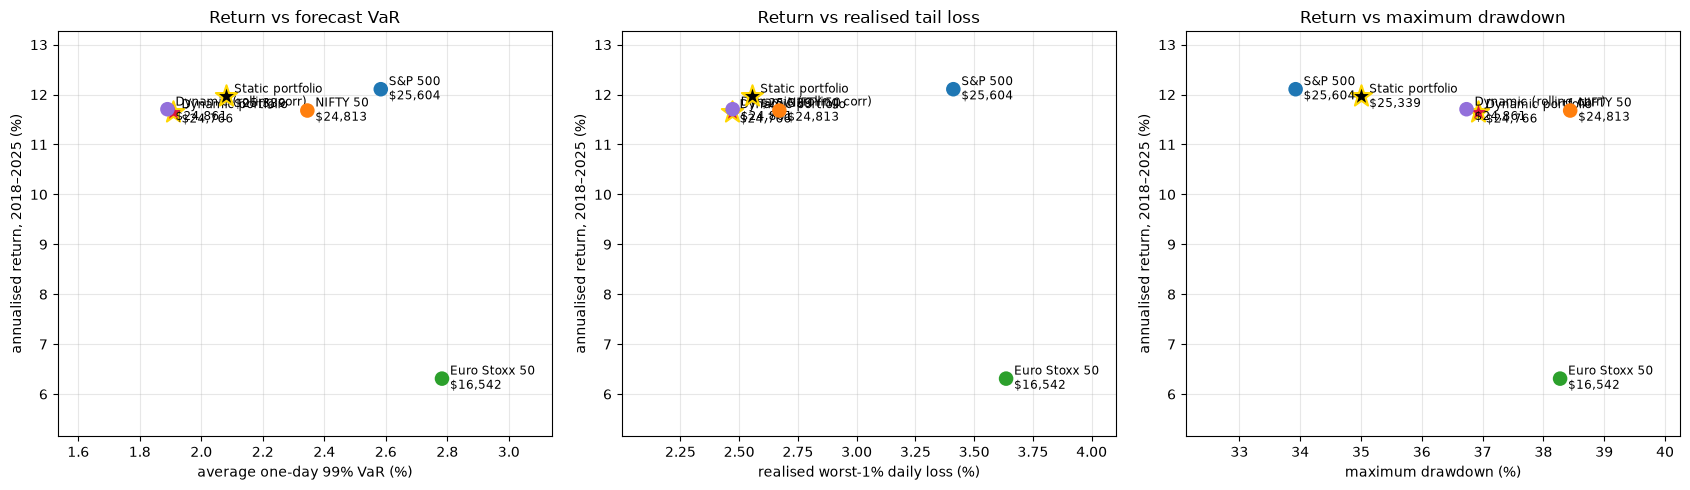

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
xs = [("Avg forecast 99% VaR (%)", "average one-day 99% VaR (%)", 1),
      ("Realised 1% daily return (%)", "realised worst-1% daily loss (%)", 1),
      ("Max drawdown", "maximum drawdown (%)", -100)]
for a, (col, xlabel, scale) in zip(ax, xs):
    for label in results:
        c = comparison[label]
        star = "portfolio" in label
        a.scatter(scale * c[col], 100 * c["Annualised return (CAGR)"], s=260 if star else 110,
                  marker="*" if star else "o", color=COLORS[label], edgecolor="gold" if star else "none",
                  linewidth=1.5, zorder=3)
        a.annotate(f"  {label}\n  ${c['Final value ($)']:,.0f}", (scale * c[col], 100 * c["Annualised return (CAGR)"]),
                   fontsize=8.5, va="center")
    a.set_xlabel(xlabel); a.set_ylabel("annualised return, 2018–2025 (%)"); a.margins(x=0.4, y=0.2)
ax[0].set_title("Return vs forecast VaR"); ax[1].set_title("Return vs realised tail loss")
ax[2].set_title("Return vs maximum drawdown")
plt.tight_layout()

### Year by year

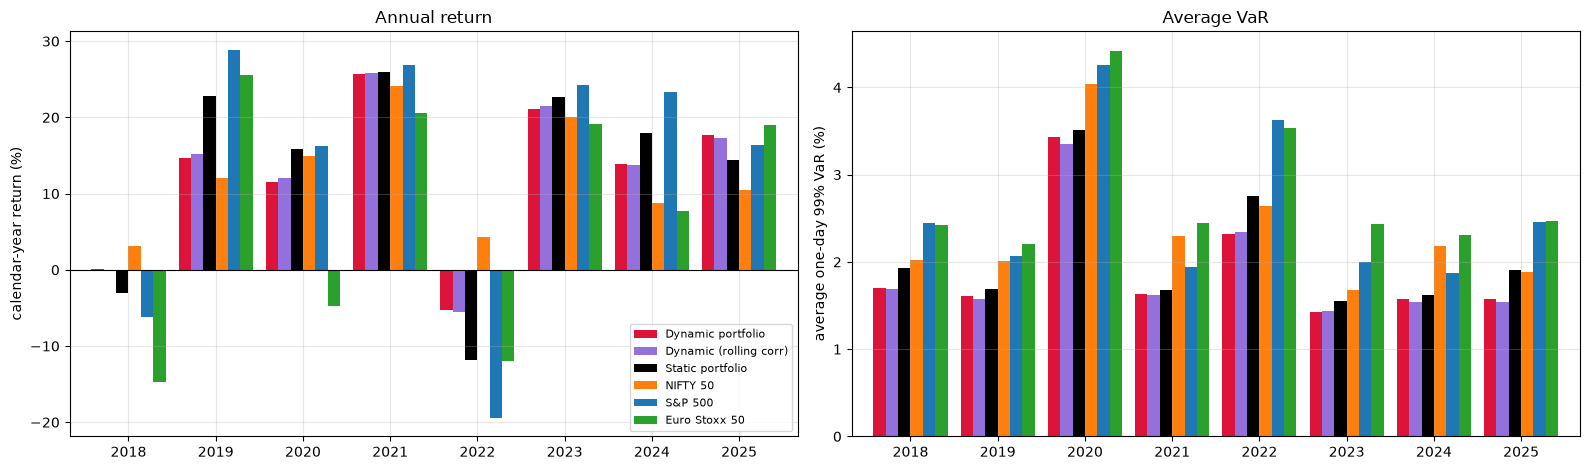

In [15]:
def yearly_stats(df):
    v = df["value"]
    ye = v.groupby(v.index.year).last()
    return pd.DataFrame({"return": ye / np.r_[INITIAL_INVESTMENT, ye.values[:-1]] - 1,
                         "avg VaR (%)": df["VaR_pct"].groupby(df.index.year).mean()})

yearly = pd.concat({label: yearly_stats(df) for label, df in results.items()}, axis=1)
yr_ret = yearly.xs("return", axis=1, level=1)
yr_var = yearly.xs("avg VaR (%)", axis=1, level=1)

fig, ax = plt.subplots(1, 2, figsize=(16, 4.8))
yr_ret.mul(100).plot(kind="bar", ax=ax[0], color=[COLORS[c] for c in yr_ret.columns], width=0.85)
ax[0].axhline(0, color="k", lw=0.8); ax[0].set_ylabel("calendar-year return (%)"); ax[0].set_xlabel("")
ax[0].set_title("Annual return"); ax[0].tick_params(axis="x", rotation=0); ax[0].legend(fontsize=8)
yr_var.plot(kind="bar", ax=ax[1], color=[COLORS[c] for c in yr_var.columns], width=0.85, legend=False)
ax[1].set_ylabel("average one-day 99% VaR (%)"); ax[1].set_xlabel("")
ax[1].set_title("Average VaR"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()

(yearly.style
   .format("{:.1%}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "return"]])
   .format("{:.2f}%", subset=pd.IndexSlice[:, pd.IndexSlice[:, "avg VaR (%)"]])
   .background_gradient(cmap="RdYlGn", vmin=-0.3, vmax=0.3, subset=pd.IndexSlice[:, pd.IndexSlice[:, "return"]])
   .background_gradient(cmap="Reds", subset=pd.IndexSlice[:, pd.IndexSlice[:, "avg VaR (%)"]]))

## 7. VaR calibration

This repeats the Stage 3 check for the portfolios. If the volatility forecast is right, the standardised portfolio return should have a standard deviation near 1. If the tail is right, its 1st percentile should match the t quantile used.

In [16]:
calib = {}
for label in ["Dynamic portfolio", ALT_LABEL, "Static portfolio"]:
    df = results[label]
    w_cols = [f"w {n}" for n in NAMES]
    # expected return term is tiny; standardise by the portfolio sigma used in the VaR
    z = df["log_ret_pct"] / df["port_sigma"]
    nu_avg = float((df[w_cols].values @ _static_inp["NU"]).mean())
    calib[label] = {
        "std of standardised return (target 1.00)": z.std(),
        "empirical 1% quantile": z.quantile(1 - VAR_LEVEL),
        "model 1% quantile (approx.)": -t_quantile(VAR_LEVEL, nu_avg),
        "breach rate": (df["log_ret_pct"] < -df["VaR_pct"]).mean(),
    }
pd.DataFrame(calib)

,Dynamic portfolio,Dynamic (rolling corr),Static portfolio
std of standardised return (target 1.00),0.9943,1.0004,0.9713
empirical 1% quantile,-2.8154,-2.8896,-2.8073
model 1% quantile (approx.),-2.5181,-2.5181,-2.5236
breach rate,0.0159,0.0178,0.0188


## 8. Sensitivity: target return × rebalancing frequency

The dynamic strategy is re-run for several targets and for weekly, monthly and quarterly rebalancing. The static portfolio for each target is shown for reference.

In [17]:
grid_targets = [0.06, 0.08, 0.10]
if TARGET_RETURN not in grid_targets:
    grid_targets = sorted(grid_targets + [TARGET_RETURN])
rows = []
for t in grid_targets:
    sw, _ = optimise(_static_inp, t)
    s_df, _ = run_strategy(freq=None, refit=False, corr_window=None, fixed_weights=sw, corr_model="rolling")
    m = metrics(s_df)
    rows.append({"target": f"{t:.0%}", "strategy": "static", "CAGR": m["Annualised return (CAGR)"],
                 "final value ($)": m["Final value ($)"], "avg VaR (%)": m["Avg forecast 99% VaR (%)"],
                 "realised 1% loss (%)": m["Realised 1% daily return (%)"], "max drawdown": m["Max drawdown"],
                 "Sharpe": m["Sharpe ratio (rf = 0)"], "breach rate": m["VaR breach rate"],
                 "avg turnover": 0.0, "infeasible dates": 0})
    for f in ["W", "M", "Q"]:
        d_df, d_log = run_strategy(freq=f, target=t)
        m = metrics(d_df, d_log)
        rows.append({"target": f"{t:.0%}", "strategy": {"W": "weekly", "M": "monthly", "Q": "quarterly"}[f],
                     "CAGR": m["Annualised return (CAGR)"], "final value ($)": m["Final value ($)"],
                     "avg VaR (%)": m["Avg forecast 99% VaR (%)"],
                     "realised 1% loss (%)": m["Realised 1% daily return (%)"], "max drawdown": m["Max drawdown"],
                     "Sharpe": m["Sharpe ratio (rf = 0)"], "breach rate": m["VaR breach rate"],
                     "avg turnover": m["Avg turnover per rebalance"], "infeasible dates": int((~d_log["feasible"]).sum())})
grid = pd.DataFrame(rows).set_index(["target", "strategy"])
(grid.style
   .format({"CAGR": "{:.2%}", "final value ($)": "${:,.0f}", "avg VaR (%)": "{:.2f}%", "realised 1% loss (%)": "{:.2f}%",
            "max drawdown": "{:.1%}", "Sharpe": "{:.2f}", "breach rate": "{:.2%}", "avg turnover": "{:.1%}",
            "infeasible dates": "{:.0f}"})
   .background_gradient(cmap="Greens", subset=["CAGR", "Sharpe"])
   .background_gradient(cmap="Reds", subset=["avg VaR (%)", "realised 1% loss (%)"]))

### Transaction costs

How much of the dynamic strategy's result survives realistic trading costs? Index futures and ETFs typically cost 2–10 basis points per trade.

In [18]:
tc_rows = []
for bps in [0, 5, 10, 25]:
    d_df, d_log = run_strategy(tc_bps=bps)
    m = metrics(d_df, d_log)
    tc_rows.append({"cost (bps)": bps, "final value ($)": m["Final value ($)"], "CAGR": m["Annualised return (CAGR)"],
                    "total costs ($)": m["Transaction costs ($)"], "Sharpe": m["Sharpe ratio (rf = 0)"]})
pd.DataFrame(tc_rows).set_index("cost (bps)").style.format(
    {"final value ($)": "${:,.0f}", "CAGR": "{:.2%}", "total costs ($)": "${:,.0f}", "Sharpe": "{:.2f}"})

,final value ($),CAGR,total costs ($),Sharpe
cost (bps),,,,
0,"$24,766",11.66%,$0,0.84
5,"$24,294",11.39%,$278,0.83
10,"$23,832",11.13%,$549,0.81
25,"$22,495",10.36%,"$1,329",0.76


## 9. Summary

In [19]:
c = comparison
print(f"Target {TARGET_RETURN:.0%} p.a., {VAR_LEVEL:.0%} VaR, rebalancing {REBALANCE_FREQ}, refit={REFIT_GARCH}, "
      f"correlations={CORR_MODEL}, costs={TRANSACTION_COST_BPS} bps\n")
print(f"{'':20s}{'final value':>12s}{'CAGR':>8s}{'avg VaR':>9s}{'real. 1%':>10s}{'max DD':>8s}{'Sharpe':>8s}{'breaches':>10s}")
for label in c.columns:
    x = c[label]
    print(f"{label:20s}{x['Final value ($)']:>12,.0f}{x['Annualised return (CAGR)']:>8.2%}"
          f"{x['Avg forecast 99% VaR (%)']:>8.2f}%{x['Realised 1% daily return (%)']:>9.2f}%"
          f"{x['Max drawdown']:>8.1%}{x['Sharpe ratio (rf = 0)']:>8.2f}{x['VaR breaches (days)']:>10.0f}")
print(f"\nDynamic average weights: " + ", ".join(f"{n} {dyn_log[n].mean():.1%}" for n in NAMES))
print(f"Target unreachable on {(~dyn_log['feasible']).sum()} of {len(dyn_log)} rebalance dates")

Target 8% p.a., 99% VaR, rebalancing M, refit=True, correlations=dcc, costs=0.0 bps

                     final value    CAGR  avg VaR  real. 1%  max DD  Sharpe  breaches
Dynamic portfolio         24,766  11.66%    1.91%     2.47%  -36.9%    0.84        33
Dynamic (rolling corr)      24,861  11.71%    1.89%     2.47%  -36.7%    0.85        37
Static portfolio          25,339  11.97%    2.08%     2.56%  -35.0%    0.82        39
NIFTY 50                  24,813  11.68%    2.34%     2.67%  -38.4%    0.75        25
S&P 500                   25,604  12.11%    2.58%     3.41%  -33.9%    0.69        33
Euro Stoxx 50             16,542   6.31%    2.78%     3.64%  -38.3%    0.42        28

Dynamic average weights: NIFTY 50 48.7%, S&P 500 43.5%, Euro Stoxx 50 7.8%
Target unreachable on 1 of 96 rebalance dates


### Findings (default settings: 8% target, 99% VaR, monthly rebalancing, GARCH and DCC refitted each month)

**DCC correlations.** DCC is a clear statistical improvement over constant correlation. On the training data the log-likelihood rises by 16 points (LR ≈ 33 on 2 degrees of freedom). The estimates stay stable through the test period: reaction $a$ = 0.014–0.023 and persistence $a + b$ = 0.945–0.982. Correlations moved a lot:

| Pair | DCC mean | DCC range | Rolling 500-day mean |
|:--|--:|--:|--:|
| NIFTY–S&P | 0.24 | 0.07 – 0.49 | 0.23 |
| NIFTY–Euro Stoxx | 0.38 | 0.22 – 0.60 | 0.37 |
| S&P–Euro Stoxx | 0.58 | 0.35 – 0.73 | 0.54 |

**Effect on the allocation: almost none.**
- **The weights barely changed.** Average weights were 48.7% NIFTY, 43.5% S&P and 7.8% Euro Stoxx, against 48.4 / 43.2 / 8.4 with rolling correlations.
- **Why:** with $a + b \approx 0.95$, a correlation shock has a half-life of about 13 trading days. So the forecast averaged over a one-month holding period is close to the long-run level, and the optimiser sees nearly the same correlation matrix either way.
- **Volatilities matter more.** The weights are driven mainly by the GARCH volatilities and by the return target.

**Effect on risk measurement: a real improvement.** DCC updates the correlations every day within the month, so the daily VaR now rises when markets start moving together:

| 2018–2025 | Dynamic (DCC) | Dynamic (rolling corr) | Static |
|:--|--:|--:|--:|
| VaR breaches (expected ≈ 21) | **33** | 37 | 39 |
| Kupiec p | 0.013 | 0.001 | 0.000 |
| Christoffersen p (clustering) | **0.111** | 0.030 | 0.211 |
| Std of standardised return | 0.99 | 1.00 | 0.97 |

With DCC, the breaches are no longer clustered: the Christoffersen test now passes. The count is still too high, because the t tail understates the worst days by about 12% (empirical 1% quantile −2.82 against −2.52). The remaining fix is a filtered-historical-simulation tail; `validation.ipynb` shows that it passes.

**Results against the alternatives.**

| 2018–2025 | Dynamic (DCC) | Dynamic (rolling) | Static | NIFTY 50 | S&P 500 | Euro Stoxx 50 |
|:--|--:|--:|--:|--:|--:|--:|
| Final value | $24,766 | $24,861 | $25,339 | $24,813 | **$25,604** | $16,542 |
| Annualised return | 11.7% | 11.7% | 12.0% | 11.7% | **12.1%** | 6.3% |
| Average 99% VaR | 1.91% | **1.89%** | 2.08% | 2.34% | 2.58% | 2.78% |
| Realised worst-1% loss | **2.47%** | **2.47%** | 2.56% | 2.67% | 3.41% | 3.64% |
| Volatility | **14.3%** | **14.3%** | 15.2% | 16.6% | 19.3% | 18.6% |
| Worst day | **$853** | $861 | $1,049 | $1,310 | $1,215 | $1,028 |
| Max drawdown | −36.9% | −36.7% | −35.0% | −38.4% | **−33.9%** | −38.3% |
| Sharpe | 0.84 | **0.85** | 0.82 | 0.75 | 0.69 | 0.42 |

- **Risk against the static portfolio.** Both dynamic versions had 6% lower volatility, about 8–9% lower average VaR and a worst day about 19% smaller.
- **2022.** The dynamic portfolio lost 5.3% that year, against 11.9% for the static portfolio and 19.4% for the S&P 500. It cut its average S&P weight from 54% in 2021 to 29%.
- **The cost.** Lower risk cost about 0.3 percentage points of return a year against the static portfolio.
- **Drawdown.** It was not improved, because monthly rebalancing cannot react within a fast crash like March 2020.

**Sensitivity.**
- **Rebalancing frequency:** monthly remains the best choice. Weekly rebalancing gives $23,633 with 7 weeks where the target can't be reached; quarterly gives $24,787.
- **Trading costs:** at 10 bps, the final value is $23,832 (11.1% a year) and the Sharpe ratio is 0.81, just below the static portfolio's.
- **Higher target:** a 10% target cannot be reached in 16 of 96 months.

**Conclusion.** Adding DCC makes the dynamic portfolio's *risk measurement* better: its VaR now reacts to correlation spikes and its breaches no longer cluster. It does not make the *allocation* better. The risk and return results are essentially the same as with rolling correlations. `validation.ipynb` tests whether the dynamic strategy, with or without DCC, beats simpler constructions over 2011–2025.